# House Prices Dataset
[kaggle](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data)

In [175]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from ipywidgets import interact
%matplotlib inline

In [16]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

path = kagglehub.competition_download('house-prices-advanced-regression-techniques')

In [55]:
df = pd.read_csv(path + '/train.csv')
df_test = pd.read_csv(path + '/test.csv')
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


### Hipoteza 1: Domy z większym parkingiem sprzedają się drożej

In [232]:
print(f'\nMin: {df['LotArea'].min()} [ft^2]\nMax: {df['LotArea'].max()} [ft^2]\n')

df['LotArea'].describe()


Min: 1300 [ft^2]
Max: 215245 [ft^2]



count      1460.000000
mean      10516.828082
std        9981.264932
min        1300.000000
25%        7553.500000
50%        9478.500000
75%       11601.500000
max      215245.000000
Name: LotArea, dtype: float64

In [255]:
print('Correlation:', df['LotArea'].corr(df['SalePrice']))

x = [df['LotArea'].quantile(x) for x in np.linspace(0, 1, 10)]
x_pairs = [(x[i], x[i + 1]) for i in range(len(x) - 1)]

by_cls = pd.DataFrame([
    {
        'MinLotArea': round(x_min),
        'MaxLotArea': round(x_max),
        'Average House Price (k$)': round((row := df.loc[(df['LotArea'] >= x_min) & (df['LotArea'] < x_max), 'SalePrice']).mean() // 1000),
        'Standard Devaition of House Price': round(row.std()),
        '5rd Min House Price (k$)': round(row.nsmallest(5).iloc[-1] // 1000),
        '5rd Max House Price (k$)': round(row.nlargest(5).iloc[-1] // 1000),
    }
    for x_min, x_max in x_pairs
])

print('\n-- Average price by house class --')
by_cls

Correlation: 0.2638433538714056

-- Average price by house class --


,MinLotArea,MaxLotArea,Average House Price (k$),Standard Devaition of House Price,5rd Min House Price (k$),5rd Max House Price (k$)
0,1300,5382,146,48908,73,251
1,5382,7200,132,46998,68,236
2,7200,8400,152,47002,68,263
3,8400,9063,156,54792,67,270
4,9063,9837,175,57648,87,315
5,9837,10766,185,67114,95,341
6,10766,11948,198,71325,90,369
7,11948,14115,227,97072,104,451
8,14115,215245,249,112274,113,555


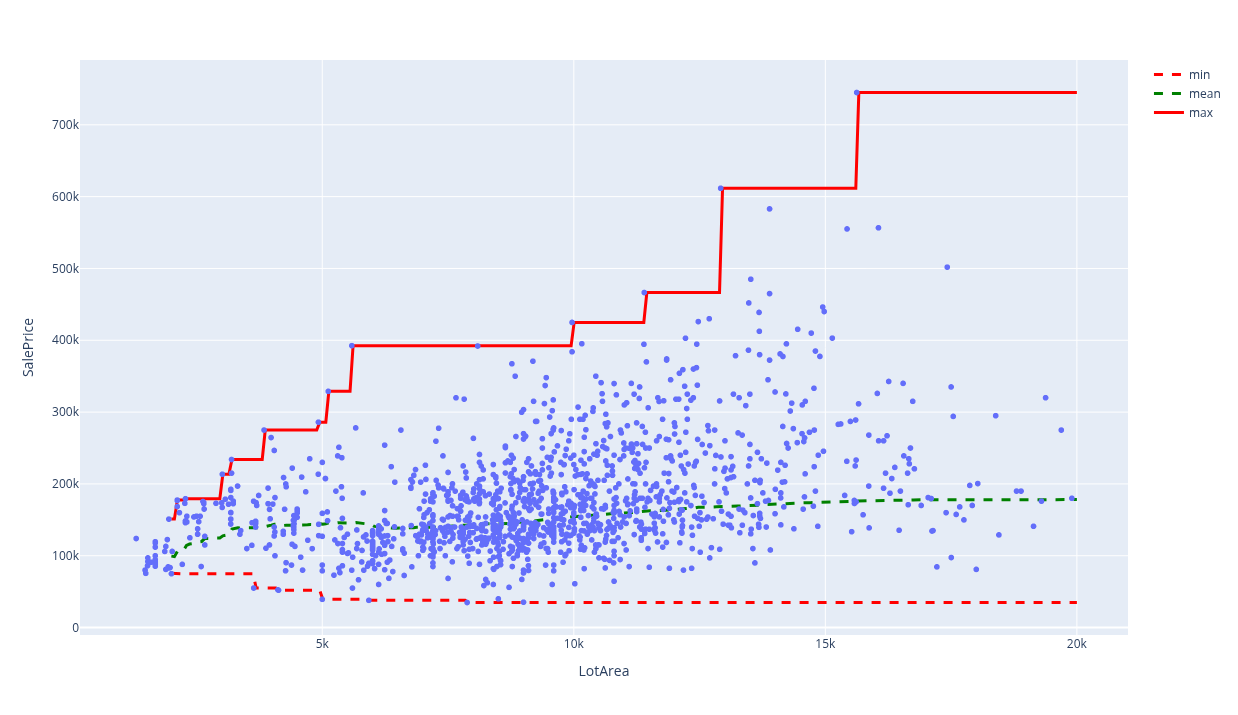

In [285]:
data = df[df['LotArea'] < 20_000]
fig = px.scatter(data, x='LotArea', y='SalePrice', width=1400, height=700)
x = np.linspace(2_000, 20_000, 300)
fig.add_trace(go.Scatter(x=x, y=[data[data['LotArea'] < end]['SalePrice'].min() for end in x], name='min', line=dict(color="red", width=3, dash='dash')))
fig.add_trace(go.Scatter(x=x, y=[data[data['LotArea'] < end]['SalePrice'].mean() for end in x], name='mean', line=dict(color="green", width=3, dash='dash')))
fig.add_trace(go.Scatter(x=x, y=[data[data['LotArea'] < end]['SalePrice'].max() for end in x], name='max', line=dict(color="red", width=3)))

In [287]:
df[df['LotArea'] < 10000]['LotArea'].corr(df['SalePrice'])

np.float64(0.2131717337385616)

<br/>

Hipoteza 1 **nie** jest w pełni prawdziwa,
lecz można zauważyć że aby dom był warty **bardzo dużo (>470k$)**
warunkiem koniecznym jest aby miał parking **przynajmniej 12k - 16k** (w danych treningowych).
<br/><br/>

In [76]:
df.loc[:0, df.columns[:20]]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003


In [83]:
df.loc[:0, df.columns[20:35]]

,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1
0,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706


In [84]:
df.loc[:0, df.columns[35:50]]

,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath
0,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2


In [85]:
df.loc[:0, df.columns[50:65]]

,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond
0,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA


In [86]:
df.loc[:0, df.columns[65:]]

,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500


## Siatka korelaci kolumn liczbowych

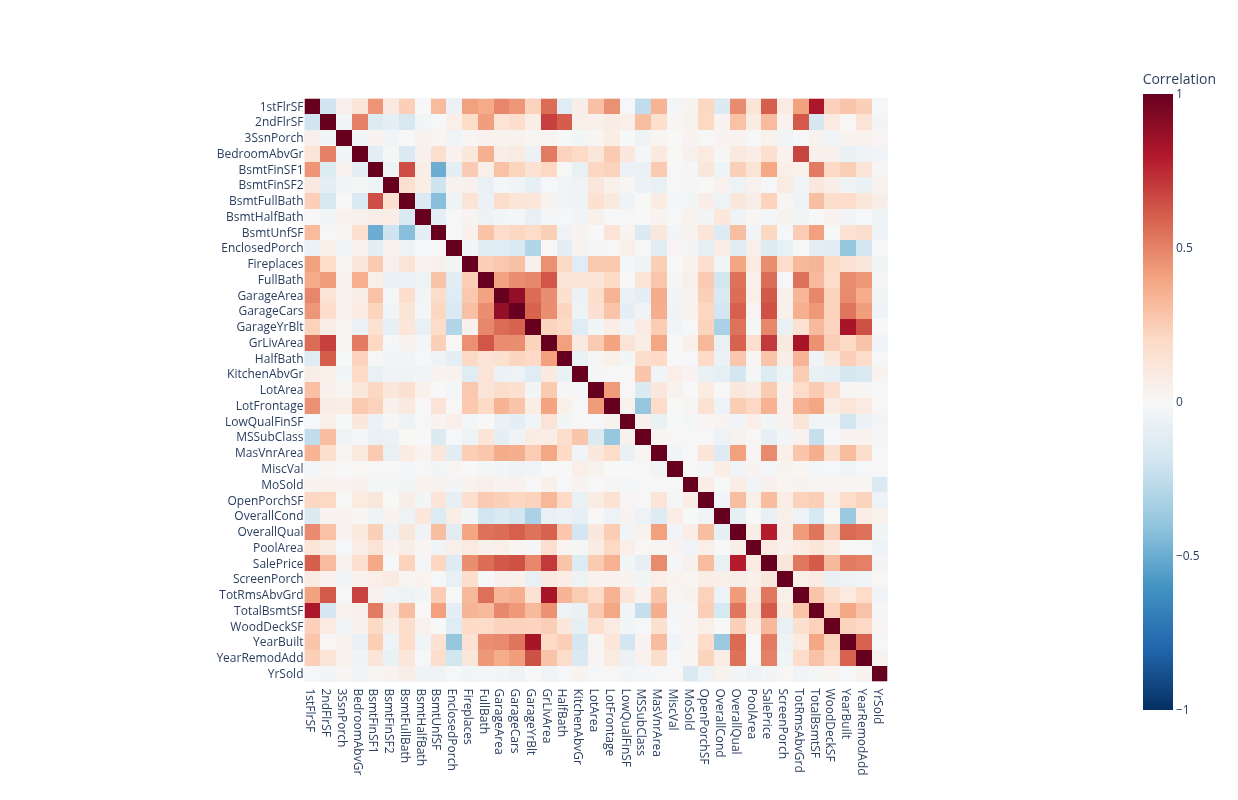

In [159]:
numeric_columns = sorted(list({col for col in df.columns if df[col].dtype.kind in ('i', 'f')} - {'Id'}))

corr = df[numeric_columns].corr()

fig = px.imshow(corr, zmin=-1, zmax=1, labels=dict(color='Correlation'), color_continuous_scale='RdBu_r')
fig.update_layout(width=800, height=800)

## Korelacje w danych
`OverallQual` rośnie podobnie do `SalePrice`.<br>
`YearBuilt` rośnie podobnie do `GarageYrBlt`.<br>
`GarageCars` rośnie podobnie do `GarageArea`.<br>
`GrLivArea` (Above grade (ground) living area square feet) rośnie podobnie do `FullBath` (Full bathrooms above grade).<br>

`MiscVal` ($Value of miscellaneous feature), `MoSold` (Month Sold) i `YrSold` (Year Sold) nie korelują z żadnymi innymi wartościami numerycznymi.<br>

In [116]:
print('Correlation:', df['YearBuilt'].corr(df['OverallCond']))
df['OverallCond'].value_counts()

Correlation: -0.37598319560699006


OverallCond
5    821
6    252
7    205
8     72
4     57
3     25
9     22
2      5
1      1
Name: count, dtype: int64

In [117]:
print('Correlation:', df['YearBuilt'].corr(df['OverallQual']))
df['OverallQual'].value_counts()

Correlation: 0.5723227689623612


OverallQual
5     397
6     374
7     319
8     168
4     116
9      43
3      20
10     18
2       3
1       2
Name: count, dtype: int64

In [ ]:
def plot_with_counts(df, x_col, y_col, labels={}, max_size=22):
    counts = (
        df.groupby([x_col, y_col])
          .size()
          .reset_index(name="count")
    )
    
    return px.scatter(counts, x=x_col, y=y_col, size='count', size_max=max_size, width=1400, height=700, labels=labels)

def round_col(df, col, nb):
    return df.assign(**{col: (df[col] // nb) * nb})

# plot_with_counts(round_col(df, 'YearBuilt', 5), 'YearBuilt', 'OverallCond')
plot_with_counts(round_col(df, 'YearBuilt', 5), 'YearBuilt', 'OverallQual')

# plot_with_counts(df, 'OverallQual', 'OverallCond', labels=dict(OverallQual='Material and finish quality', OverallCond='Condition rating'), max_size=40)


### Hipoteza 2: Im młodszy budynek tym lepsza jest jego całościowa jakość


Korelacja roku wybudowania z jakością budynku: 0.572



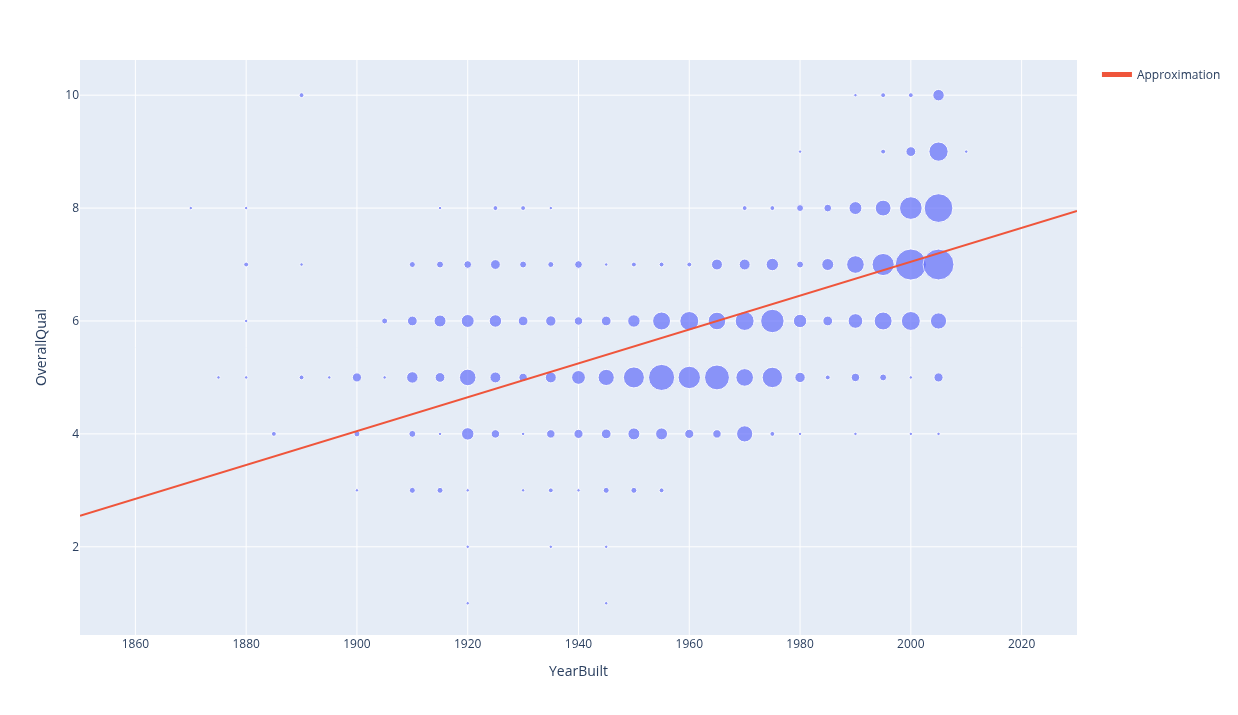

In [215]:
print(f'\nKorelacja roku wybudowania z jakością budynku: {df['YearBuilt'].corr(df['OverallQual']):.3f}\n')

fig = plot_with_counts(round_col(df, 'YearBuilt', 5), 'YearBuilt', 'OverallQual')
x = np.linspace(1850, 2030, 50)
fig.add_trace(go.Scatter(x=x, y=3/100 * (x - 1765), name='Approximation'))
fig

### Hipoteza 2 jest prawdziwa, jakość budynków ulegała poprawie od ~1880 roku do ~2010 roku